# Robustness of Vision Watermark Detection Against Adversarial Attacks
**DSC 261 final project** — Emily Cheng, Seongho Kim, Paul Lai, Kevin Lin, Samantha Lin, Ariel Wang

We embed a fixed pseudorandom ±λ watermark in CIFAR-10 images, fine-tune an ImageNet-pretrained
ResNet50 to detect it, and test four hypotheses:

| | Hypothesis |
|---|---|
| **H1** | Detection accuracy falls as the attack budget ε grows |
| **H2** | PGD evades detection more effectively than FGSM |
| **H3** | Adversarially trained detectors resist attacks better than a standard detector |
| **H4** | A stronger watermark (larger λ) is more robust but lowers image fidelity |

**How this notebook is organised.** All model, attack, training and evaluation code lives in
[`wmrobust.py`](wmrobust.py); [`run_experiments.py`](run_experiments.py) trains and evaluates all 8
detectors (≈ several GPU-hours) and saves checkpoints and CSVs under `runs/full/`. This notebook
loads those results, so it runs in minutes without a GPU. Set `TRAIN = True` to re-run everything.

**LLM disclosure.** The final code in this notebook and in `wmrobust.py`, `run_experiments.py` and
`make_report_assets.py` was written with assistance from Claude (Anthropic) and reviewed by the team.
It builds on the team's exploratory notebook (`main revised Sam.ipynb`), parts of which were written with
assistance from ChatGPT.

In [1]:
import subprocess, sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import Image, display

import wmrobust as wm
import make_report_assets as assets

TRAIN = False   # True: train + evaluate all detectors (GPU strongly recommended)
RUN_DIR = Path("runs/full")
if not (RUN_DIR / "all_results.csv").exists() and not TRAIN:
    RUN_DIR = Path("runs/quick")   # falls back to the smoke-test run
device = wm.get_device()
pd.set_option("display.precision", 4)
print("device:", wm.device_name(device), "| torch", torch.__version__, "| results from:", RUN_DIR)

device: mps | torch 2.8.0 | results from: runs/full


## 1. Data and watermark
Originals are split **before** watermarking (45,000 train / 5,000 validation, stratified by class;
10,000 test). Half of each class in train/validation is watermarked. The test set is **paired**:
each original appears once clean and once watermarked (20,000 images), so it is exactly balanced
and the two versions of each image can be compared.

In [2]:
cifar_train, cifar_test = wm.load_cifar10("./data")
splits = wm.make_splits(cifar_train, cifar_test)
targets = np.asarray(cifar_train.targets)
train_labels = wm.balanced_watermark_labels(targets[splits["train"]], wm.SEED + 10)
val_labels = wm.balanced_watermark_labels(targets[splits["val"]], wm.SEED + 11)
pd.DataFrame([
    {"partition": "train", "originals": len(splits["train"]), "clean": int((train_labels == 0).sum()), "watermarked": int(train_labels.sum())},
    {"partition": "validation", "originals": len(splits["val"]), "clean": int((val_labels == 0).sum()), "watermarked": int(val_labels.sum())},
    {"partition": "test (paired)", "originals": len(splits["test"]), "clean": len(splits["test"]), "watermarked": len(splits["test"])},
])

,partition,originals,clean,watermarked
0,train,45000,22500,22500
1,validation,5000,2500,2500
2,test (paired),10000,10000,10000


The watermark is $x_W = \mathrm{clip}_{[0,1]}(x + \lambda W)$ with a fixed $W \in \{-1,+1\}^{3\times32\times32}$
(seed 2026). The main experiments use λ = 0.02 (≈ 5/255).

In [3]:
pattern = wm.make_watermark_pattern()
test_u8 = wm.to_uint8_tensor(cifar_test, splits["test"])
x0 = test_u8[:4].float() / 255
x1 = wm.add_watermark(x0, 0.02, pattern)

fig, axes = plt.subplots(2, 5, figsize=(11, 4.6))
axes[0, 0].imshow((pattern.permute(1, 2, 0) + 1) / 2); axes[0, 0].set_title("pattern W (RGB)", fontsize=9)
axes[1, 0].imshow(pattern[0], cmap="gray"); axes[1, 0].set_title("W, red channel", fontsize=9)
for j in range(4):
    axes[0, j + 1].imshow(x1[j].permute(1, 2, 0)); axes[0, j + 1].set_title(f"watermarked #{j}", fontsize=9)
    diff = ((x1[j] - x0[j]) / 0.02 + 1) / 2   # amplified for display only
    axes[1, j + 1].imshow(diff.clamp(0, 1).permute(1, 2, 0)); axes[1, j + 1].set_title("difference (amplified)", fontsize=9)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

fidelity = pd.DataFrame([{"lambda": lam, **wm.watermark_fidelity(test_u8, lam, pattern, device)}
                         for lam in [0.005, 0.01, 0.02, 0.05]])
fidelity.rename(columns={"wm_psnr": "PSNR (dB)", "wm_ssim": "SSIM"})

/var/folders/q1/c60kmrg156168vv6s1dn1jr80000gn/T/ipykernel_6976/1808774262.py:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


,lambda,PSNR (dB),SSIM
0,0.005,46.0551,0.9974
1,0.010,40.0468,0.9899
2,0.020,34.0439,0.9632
3,0.050,26.1299,0.8427


## 2. Detector and attacks
* **Detector** (`wm.Detector`): ImageNet-pretrained ResNet50, 2-way head. ImageNet normalization is the
  model's first layer, so attacks work in ordinary [0, 1] pixel units.
* **FGSM** (`wm.fgsm`): one step $x + \epsilon\,\mathrm{sign}(\nabla_x L)$, clipped to [0, 1].
* **PGD** (`wm.pgd`): 10 steps of size ε/4 from a random start, projected onto the $L_\infty$ ball of radius ε.
* The attacker uses the true label: watermarked images are pushed toward "clean" (**evasion**), clean
  images toward "watermarked" (**forgery**).
* **Adversarial training** (`wm.train_detector`): each batch = clean images + their FGSM/PGD versions.
  We train for a fixed number of epochs and keep the best validation epoch (replacing the proposal's
  noisy last-batch early-stopping rule).

**A limit we prove in the report (Sec. 3.7).** If ε ≥ λ/2, the midpoint $z=(x_0+x_1)/2$ of a clean image
and its watermarked copy is within ε of both. Whatever a detector says about $z$, one of the two copies
can be moved there and misclassified. So for ε ≥ λ/2 *no* detector can get both copies right, and
paired accuracy is capped at 50%. With λ = 0.02 that boundary is ε = 0.01, which is why adversarial
training uses ε ∈ {0.005, 0.01} only.

Quick demo with the trained standard detector:

In [4]:
ckpt = RUN_DIR / "checkpoints" / "std_l0.02.pt"
if ckpt.exists():
    model = wm.Detector(pretrained=False).to(device)
    model.load_state_dict(torch.load(ckpt, map_location=device, weights_only=False)["model"])
    model.eval()
    x = wm.add_watermark(test_u8[:6].to(device).float() / 255, 0.02, pattern)
    y = torch.ones(6, dtype=torch.long, device=device)
    rows = {}
    for name, xa in [("watermarked", x), ("FGSM eps=0.01", wm.fgsm(model, x, y, 0.01)),
                     ("PGD eps=0.01", wm.pgd(model, x, y, 0.01))]:
        with torch.no_grad():
            rows[name] = model(xa).softmax(1)[:, 1].cpu().numpy()
    display(pd.DataFrame(rows).style.format("{:.3f}").set_caption("P(watermarked) for 6 watermarked test images"))
else:
    print("No checkpoint yet; run the experiments first.")

,watermarked,FGSM eps=0.01,PGD eps=0.01
0,1.000,0.999,0.000
1,0.882,0.039,0.000
2,1.000,0.767,0.000
3,0.987,0.113,0.000
4,1.000,0.867,0.000
5,1.000,0.806,0.000


## 3. Running the experiments
`run_experiments.py --exp all` trains 8 detectors and evaluates each, clean and under FGSM/PGD at
ε ∈ {0.0025, 0.005, 0.01, 0.02, 0.03}:

| model | training | λ |
|---|---|---|
| `std_l0.02` | standard | 0.02 |
| `fgsm_e0.005_l0.02`, `fgsm_e0.01_l0.02` | FGSM adversarial, ε = 0.005 / 0.01 | 0.02 |
| `pgd_e0.005_l0.02`, `pgd_e0.01_l0.02` | PGD adversarial, ε = 0.005 / 0.01 | 0.02 |
| `std_l0.005`, `std_l0.01`, `std_l0.05` | standard | 0.005 / 0.01 / 0.05 |

In [5]:
if TRAIN:
    subprocess.run([sys.executable, "run_experiments.py", "--exp", "all", "--out", str(RUN_DIR)], check=True)
meta = json.loads((RUN_DIR / "run_meta.json").read_text())
print({k: meta[k] for k in ["device", "epochs", "n_train", "n_val", "n_test_originals", "attack_eps", "pgd_alpha"]})
print(f"total compute: {sum(meta['timings_sec'].values()) / 3600:.2f} h")

{'device': 'NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition MIG 1g.24gb', 'epochs': 10, 'n_train': 45000, 'n_val': 5000, 'n_test_originals': 10000, 'attack_eps': [0.0025, 0.005, 0.01, 0.02, 0.03], 'pgd_alpha': 'eps/4, random start'}
total compute: 0.86 h


## 4. Results

In [6]:
df = pd.read_csv(RUN_DIR / "all_results.csv")
assets.main(["--run", str(RUN_DIR), "--dest", "report"])   # also writes the report's figures/tables
FIG = Path("report/figures")
label = lambda r: "Standard" if r.train_adv == "none" else f"{r.train_adv.upper()}-AT eps={r.train_eps:g}"
df["detector"] = df.apply(label, axis=1)
clean = df[df.attack == "none"][["detector", "strength", "accuracy", "TPR", "FPR", "precision", "wm_psnr"]]
clean.rename(columns={"strength": "lambda", "wm_psnr": "watermark PSNR"}).style.format(precision=4).hide(axis="index")

wrote ['report/figures/fig_examples.pdf', 'report/figures/fig_h1_h2_baseline.pdf', 'report/figures/fig_h3_adv_training.pdf', 'report/figures/fig_h4_lambda.pdf', 'report/figures/fig_training.pdf'] ['report/generated/numbers.tex', 'report/generated/table_clean.tex', 'report/generated/table_lambda.tex', 'report/generated/table_robust.tex', 'report/generated/table_worst.tex']


detector,lambda,accuracy,TPR,FPR,precision,watermark PSNR
FGSM-AT eps=0.005,0.0200,0.9715,0.9955,0.0526,0.9498,34.0439
FGSM-AT eps=0.01,0.0200,0.9641,0.9845,0.0563,0.9459,34.0439
PGD-AT eps=0.005,0.0200,0.9415,0.9652,0.0821,0.9216,34.0439
PGD-AT eps=0.01,0.0200,0.8602,0.7630,0.0425,0.9472,34.0439
Standard,0.0050,0.6202,0.5913,0.3509,0.6276,46.0551
Standard,0.0100,0.8643,0.8783,0.1497,0.8544,40.0468
Standard,0.0200,0.9774,0.9813,0.0266,0.9736,34.0439
Standard,0.0500,0.9987,0.9987,0.0014,0.9986,26.1299


### H1 and H2: the standard detector under FGSM and PGD (λ = 0.02)

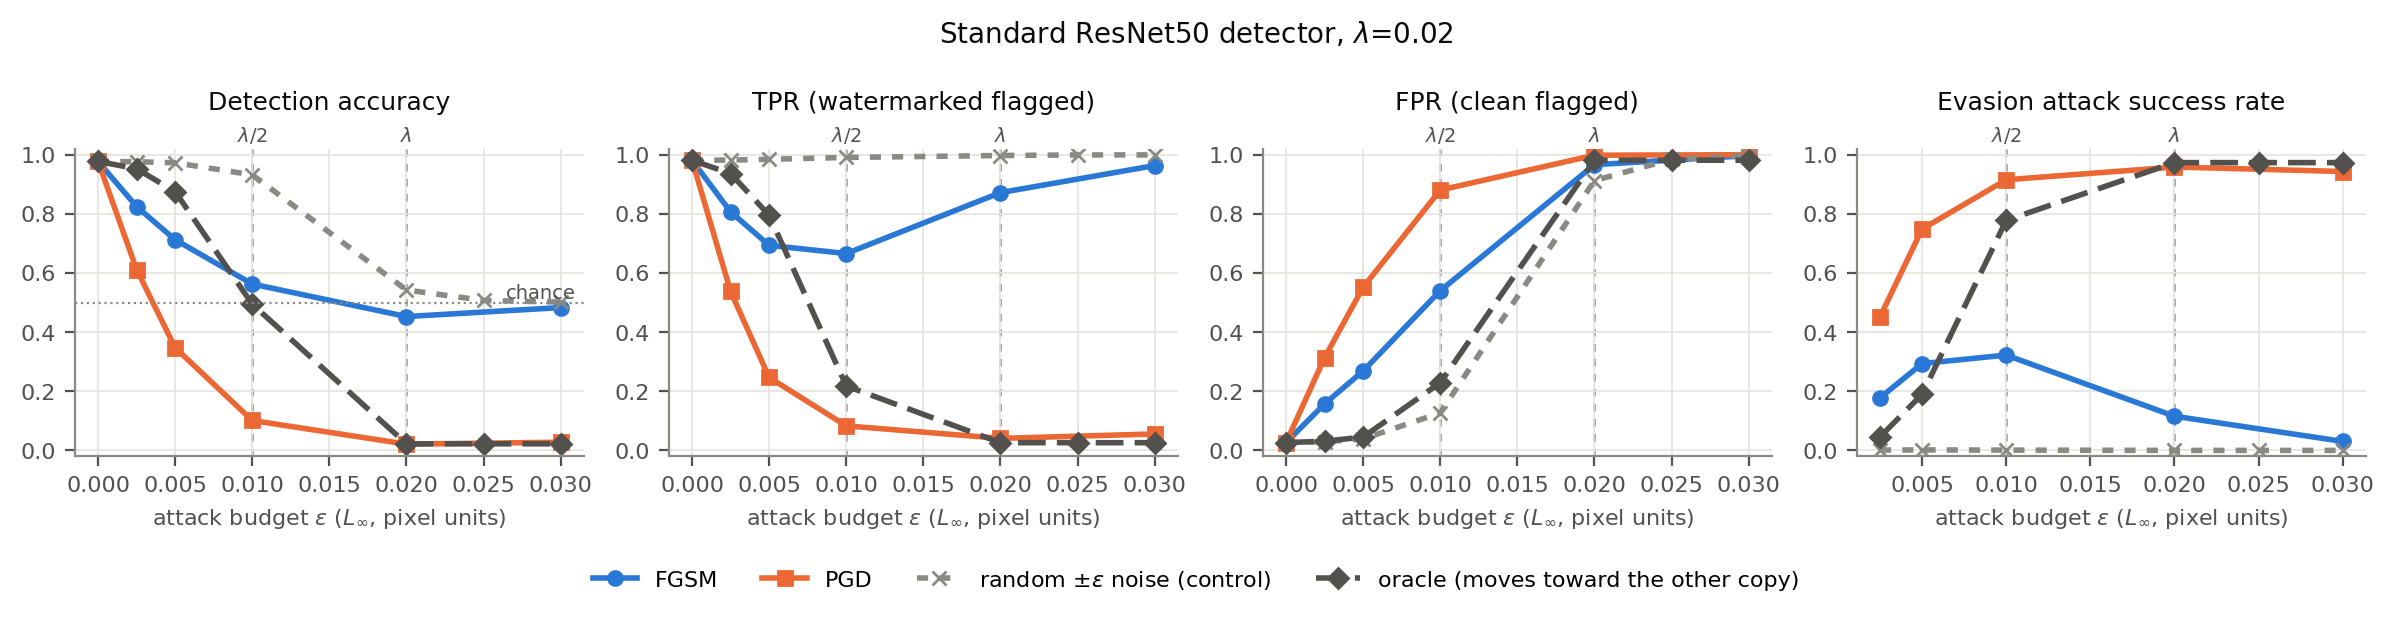

FPR                     TPR                 accuracy          \
attack    fgsm    none     pgd    fgsm    none     pgd     fgsm    none   
eps                                                                       
0.0000     NaN  0.0266     NaN     NaN  0.9813     NaN      NaN  0.9774   
0.0025  0.1576     NaN  0.3140  0.8067     NaN  0.5375   0.8246     NaN   
0.0050  0.2687     NaN  0.5519  0.6936     NaN  0.2467   0.7124     NaN   
0.0100  0.5402     NaN  0.8806  0.6658     NaN  0.0831   0.5628     NaN   
0.0200  0.9663     NaN  0.9983  0.8718     NaN  0.0408   0.4528     NaN   
0.0300  0.9971     NaN  1.0000  0.9633     NaN  0.0557   0.4831     NaN   

               evasion_asr             psnr           
attack     pgd        fgsm     pgd     fgsm      pgd  
eps                                                   
0.0000     NaN         NaN     NaN      NaN      NaN  
0.0025  0.6118      0.1781  0.4523  52.0742  54.5110  
0.0050  0.3474      0.2938  0.7486  46.0577  49.0105  
0.0100  0.1013      0.3224  0.9153  40.0447  43.3827  
0.0200  0.0213      0.1158  0.9584  34.0363  37.6717  
0.0300  0.0278      0.0306  0.9432  30.5318  34.2806

In [7]:
display(Image(FIG / "fig_h1_h2_baseline.png"))
base = df[df.model == "std_l0.02"]
base.pivot_table(index="eps", columns="attack", values=["accuracy", "TPR", "FPR", "evasion_asr", "psnr"]).round(4)

In [8]:
def check_h1(d, tol=0.005):
    out = []
    for (model, attack), g in d[d.attack != "none"].groupby(["model", "attack"]):
        accs = [d[(d.model == model) & (d.attack == "none")].accuracy.iloc[0]] + list(g.sort_values("eps").accuracy)
        out.append({"model": model, "attack": attack,
                    "accuracy falls with eps": all(b <= a + tol for a, b in zip(accs, accs[1:])),
                    "clean acc": accs[0], "acc at max eps": accs[-1]})
    return pd.DataFrame(out)

def check_h2(d):
    piv = d[d.attack != "none"].pivot_table(index=["model", "eps"], columns="attack", values="evasion_asr")
    piv["PGD - FGSM"] = piv["pgd"] - piv["fgsm"]
    return piv

print("H1 — monotone decrease of accuracy with eps (0.5 pp tolerance):")
display(check_h1(df).round(4))
h2 = check_h2(df)
print(f"H2 — PGD evasion ASR >= FGSM in {(h2['PGD - FGSM'] >= -1e-9).mean():.0%} of (model, eps) cells")
display(h2.round(4))

H1 — monotone decrease of accuracy with eps (0.5 pp tolerance):


,model,attack,accuracy falls with eps,clean acc,acc at max eps
0,fgsm_e0.005_l0.02,fgsm,False,0.9714,0.4967
1,fgsm_e0.005_l0.02,pgd,False,0.9714,0.0912
2,fgsm_e0.01_l0.02,fgsm,True,0.9641,0.4969
3,fgsm_e0.01_l0.02,pgd,False,0.9641,0.2843
4,pgd_e0.005_l0.02,fgsm,False,0.9416,0.4890
5,pgd_e0.005_l0.02,pgd,False,0.9416,0.4552
6,pgd_e0.01_l0.02,fgsm,True,0.8602,0.4582
7,pgd_e0.01_l0.02,pgd,True,0.8602,0.2100
8,std_l0.005,fgsm,False,0.6202,0.3977
9,std_l0.005,pgd,False,0.6202,0.0202


H2 — PGD evasion ASR >= FGSM in 98% of (model, eps) cells


attack                      fgsm     pgd  PGD - FGSM
model             eps                               
fgsm_e0.005_l0.02 0.0025  0.0269  0.0882      0.0613
                  0.0050  0.0811  0.2981      0.2171
                  0.0100  0.1323  0.6720      0.5397
                  0.0200  0.0246  0.8371      0.8125
                  0.0300  0.0048  0.8169      0.8121
fgsm_e0.01_l0.02  0.0025  0.0652  0.1402      0.0750
                  0.0050  0.1188  0.3039      0.1851
                  0.0100  0.1337  0.5421      0.4084
                  0.0200  0.0218  0.5914      0.5695
                  0.0300  0.0036  0.4244      0.4208
pgd_e0.005_l0.02  0.0025  0.0510  0.0534      0.0024
                  0.0050  0.0798  0.0773     -0.0025
                  0.0100  0.0851  0.1155      0.0305
                  0.0200  0.0284  0.1202      0.0918
                  0.0300  0.0091  0.0765      0.0673
pgd_e0.01_l0.02   0.0025  0.1683  0.2187      0.0505
                  0.0050  0.2710  0.4090      0.1380
                  0.0100  0.3591  0.6456      0.2865
                  0.0200  0.2123  0.7320      0.5197
                  0.0300  0.0995  0.6904      0.5910
std_l0.005        0.0025  0.6841  0.9731      0.2890
                  0.0050  0.6489  0.9905      0.3416
                  0.0100  0.4774  0.9917      0.5143
                  0.0200  0.3452  0.9817      0.6366
                  0.0300  0.3115  0.9667      0.6552
std_l0.01         0.0025  0.4167  0.7683      0.3516
                  0.0050  0.4744  0.9241      0.4496
                  0.0100  0.3109  0.9661      0.6551
                  0.0200  0.0942  0.9524      0.8582
                  0.0300  0.0623  0.9316      0.8693
std_l0.02         0.0025  0.1781  0.4523      0.2741
                  0.0050  0.2938  0.7486      0.4548
                  0.0100  0.3224  0.9153      0.5929
                  0.0200  0.1158  0.9584      0.8427
                  0.0300  0.0306  0.9432      0.9127
std_l0.05         0.0025  0.0186  0.0714      0.0528
                  0.0050  0.0421  0.2379      0.1959
                  0.0100  0.0871  0.5275      0.4404
                  0.0200  0.1142  0.7717      0.6575
                  0.0300  0.0761  0.8360      0.7599

#### Controls: random ±ε noise and the oracle attacker (`controls.py`)
* **Random noise.** FGSM's evasion success *falls* at large ε while it flags almost every clean image.
  Is the detector reacting to the specific pattern W, or to any dense ±noise? We add **random** ±ε sign
  noise (same size and structure as an FGSM step, no knowledge of the model).
* **Oracle attacker.** Knows both copies of each image and moves each one toward the midpoint or toward
  the other copy (whichever fools the detector). At ε ≥ λ/2 this realises the report's proposition:
  at most one copy of each image can be classified correctly.

In [9]:
ctl_path = RUN_DIR / "controls.csv"
if ctl_path.exists():
    ctl = pd.read_csv(ctl_path)
    ctl["detector"] = ctl.apply(label, axis=1)
    noise, oracle = ctl[ctl.attack == "noise"], ctl[ctl.attack == "oracle"]
    display(noise[noise.model == "std_l0.02"][["eps", "accuracy", "TPR", "FPR", "evasion_asr"]]
            .style.format(precision=4).hide(axis="index")
            .set_caption("Standard detector (λ=0.02) under random ±eps noise"))
    lam02 = pd.concat([df[(df.strength == 0.02) & (df.attack == "pgd")], oracle[oracle.strength == 0.02]])
    display(lam02.pivot_table(index="eps", columns=["detector", "attack"], values="accuracy").round(3)
            .style.set_caption("Accuracy under PGD vs. the oracle attacker (λ=0.02); oracle <= 0.5 at eps >= 0.01"))
    print("max oracle accuracy at eps >= lambda/2:",
          round(oracle[oracle.eps >= oracle.strength / 2 - 1e-9].accuracy.max(), 4))
else:
    print("run `python controls.py --run", RUN_DIR, "` first")

eps,accuracy,TPR,FPR,evasion_asr
0.0025,0.9762,0.9820,0.0296,0.0012
0.0050,0.9727,0.9844,0.0390,0.0017
0.0100,0.9319,0.9908,0.1269,0.0011
0.0200,0.5424,0.9973,0.9125,0.0002
0.0250,0.5073,0.9992,0.9845,0.0001
0.0300,0.5018,0.9994,0.9959,0.0001
0.0400,0.5002,0.9996,0.9992,0.0001
0.0500,0.5001,0.9996,0.9994,0.0002


max oracle accuracy at eps >= lambda/2: 0.4988


### H3: adversarial training (λ = 0.02)

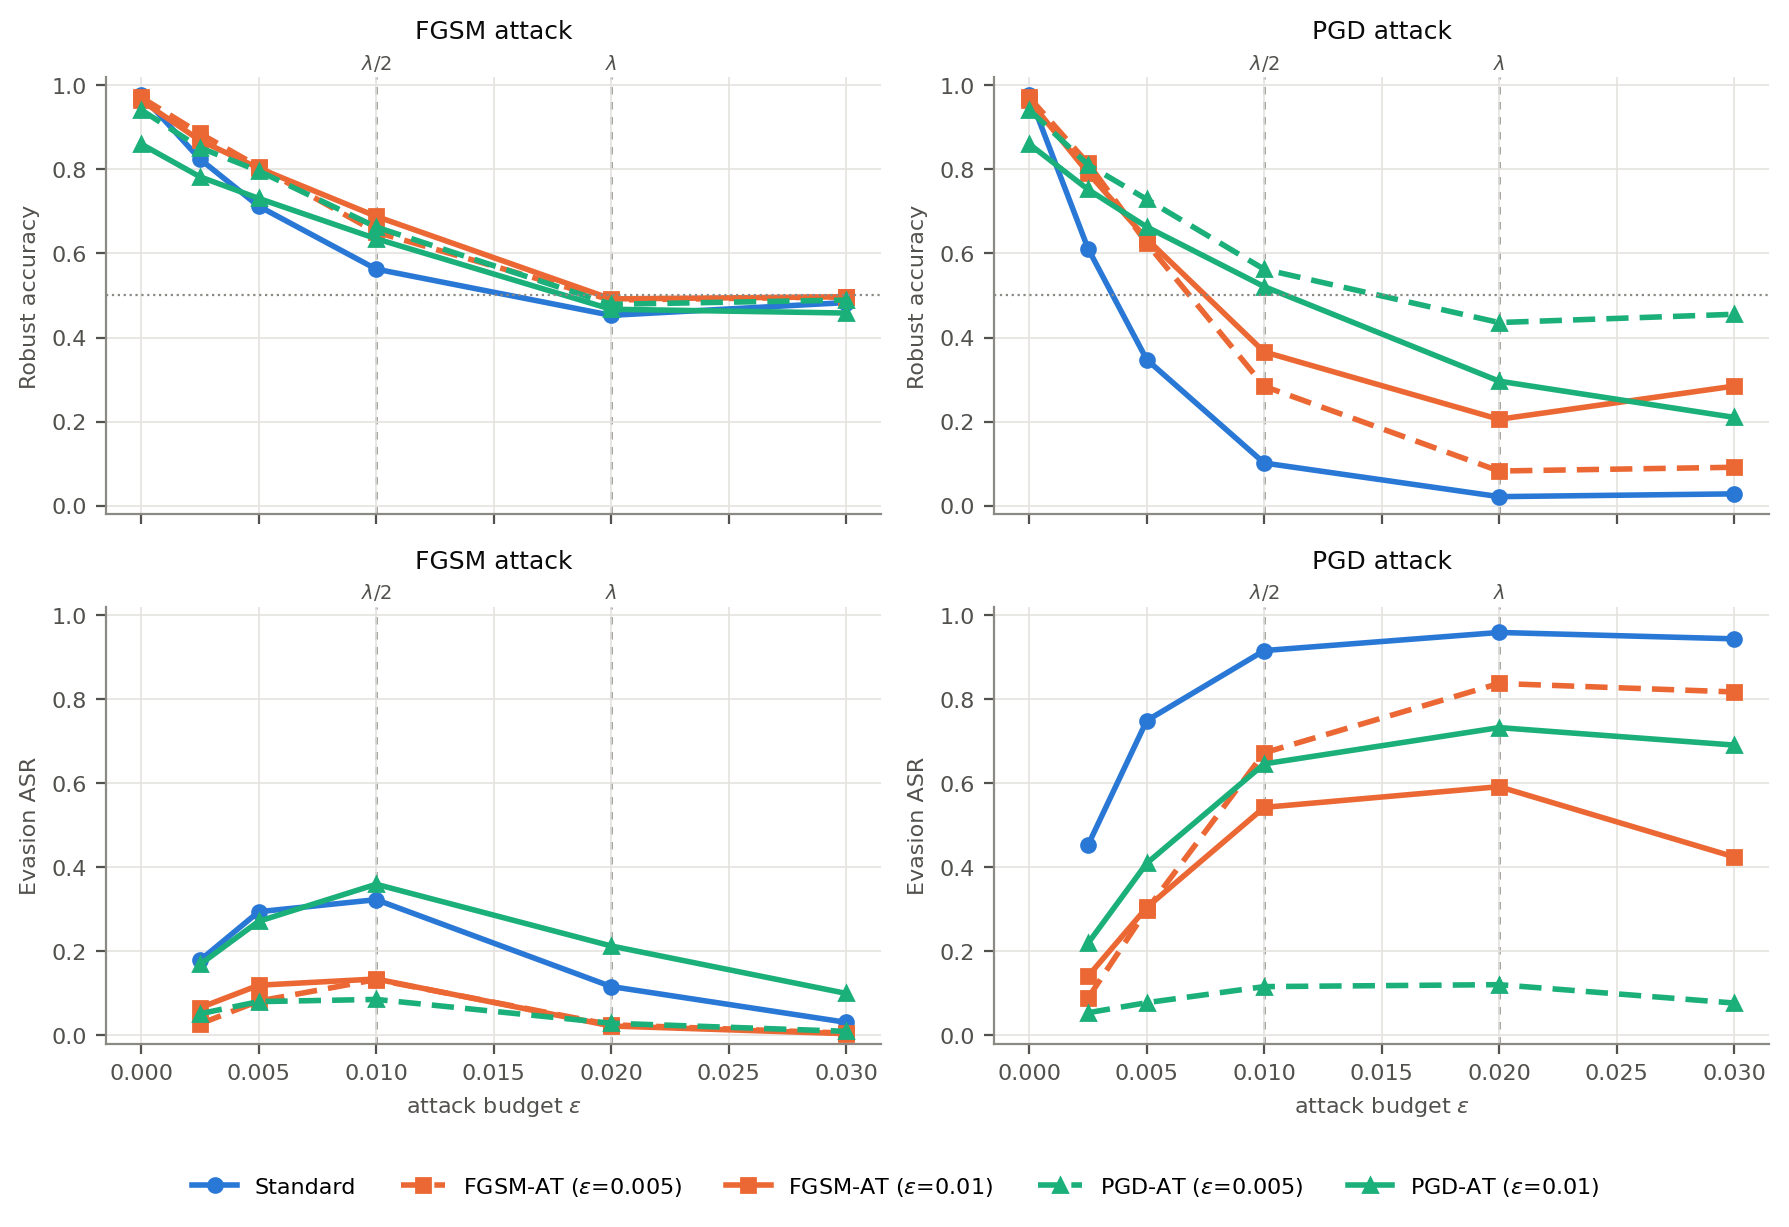

In [10]:
display(Image(FIG / "fig_h3_adv_training.png"))
lam = 0.02
sub = df[(df.strength == lam) & (df.attack != "none")]
std = sub[sub.model == "std_l0.02"].set_index(["attack", "eps"]).evasion_asr
rows = []
for model, g in sub[sub.model != "std_l0.02"].groupby("model"):
    g = g.set_index(["attack", "eps"])
    for (attack, eps), r in g.iterrows():
        rows.append({"detector": r.detector, "attack": attack, "eps": eps,
                     "regime": "eps < lambda/2" if eps < lam / 2 - 1e-9 else ("eps = lambda/2" if abs(eps - lam / 2) < 1e-9 else "eps > lambda/2"),
                     "evasion ASR": r.evasion_asr, "standard ASR": std[(attack, eps)],
                     "reduction": std[(attack, eps)] - r.evasion_asr, "accuracy": r.accuracy})
h3 = pd.DataFrame(rows)
display(h3.pivot_table(index="detector", columns=["attack", "regime"], values="reduction", aggfunc="mean").round(4)
        .style.set_caption("Mean reduction in evasion ASR vs. the standard detector (positive = more robust)"))

### H4: watermark strength (standard detectors)

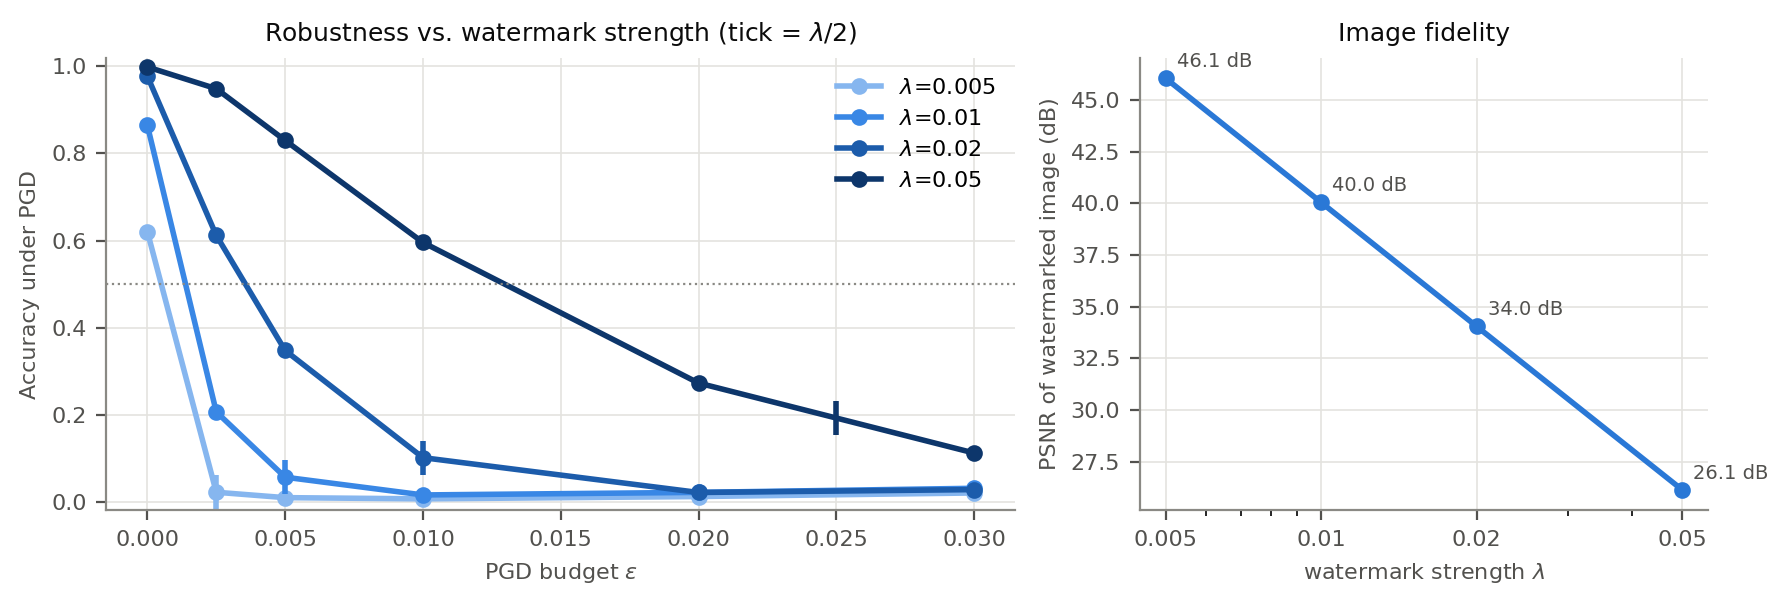

PGD accuracy by attack eps (rows) and watermark strength lambda (columns):


strength,0.005,0.010,0.020,0.050
eps,,,,
0.0025,0.0218,0.2064,0.6118,0.9486
0.005,0.0094,0.0564,0.3474,0.8298
0.01,0.0066,0.0156,0.1013,0.5956
0.02,0.0120,0.0215,0.0213,0.2726
0.03,0.0202,0.0309,0.0278,0.1119
clean,0.6202,0.8643,0.9774,0.9986
watermark PSNR (dB),46.0551,40.0468,34.0439,26.1299


In [11]:
display(Image(FIG / "fig_h4_lambda.png"))
sw = df[df.train_adv == "none"]
h4 = sw[sw.attack == "pgd"].pivot_table(index="eps", columns="strength", values="accuracy")
h4.loc["clean"] = sw[sw.attack == "none"].set_index("strength").accuracy
h4.loc["watermark PSNR (dB)"] = sw[sw.attack == "none"].set_index("strength").wm_psnr
print("PGD accuracy by attack eps (rows) and watermark strength lambda (columns):")
display(h4.round(4))

### Examples and training curves

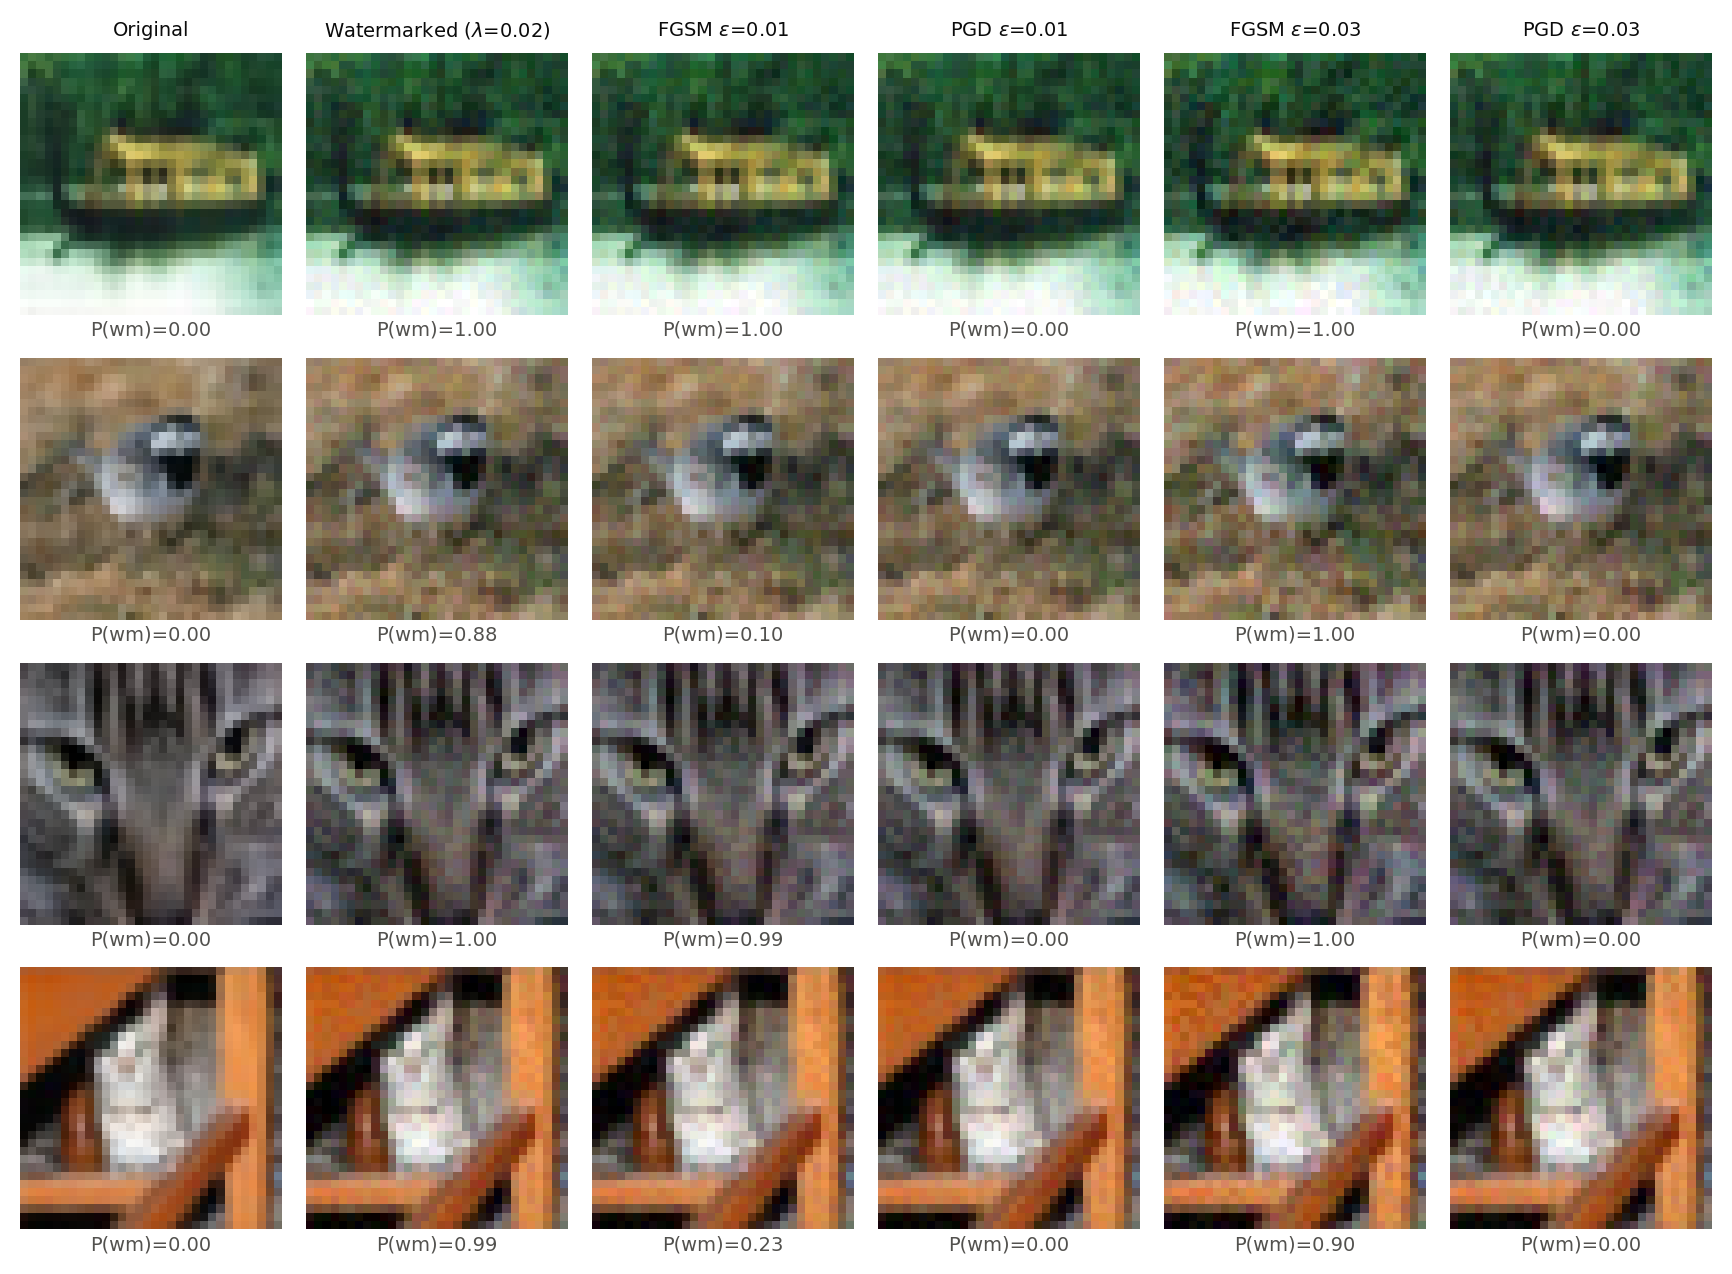

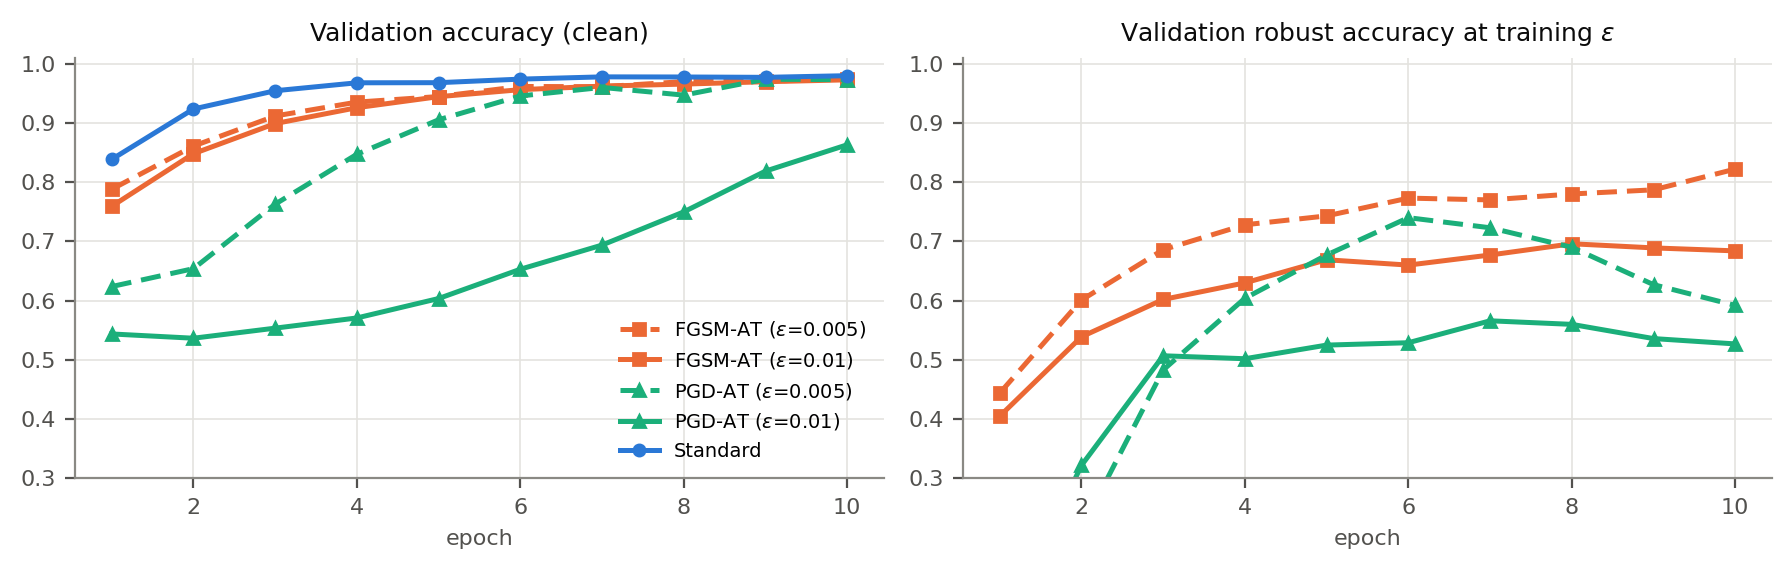

In [12]:
for name in ["fig_examples.png", "fig_training.png"]:
    if (FIG / name).exists():
        display(Image(FIG / name))

## 5. Conclusions

| | Hypothesis | Result |
|---|---|---|
| **H1** | Accuracy falls as ε grows | **Holds.** PGD: 97.7% clean → 61.2% at ε = 0.0025 (λ/8) → 10.1% at λ/2 → 2.1% at λ. FGSM falls until ε ≈ λ, then stalls near 50%. |
| **H2** | PGD beats FGSM | **Holds** for all 8 detectors: PGD lowers accuracy more in 40/40 cases, higher evasion success in 39/40 (one 0.2-pt tie). |
| **H3** | Adversarial training helps | **Holds below λ/2.** PGD-AT at ε = 0.005 cuts PGD evasion at ε = 0.005 from 74.9% to 7.7%, for 3.5 pts of clean accuracy. Training at λ/2 backfires; nothing survives past λ/2. |
| **H4** | Stronger watermark = more robust, less fidelity | **Holds.** PGD accuracy at ε = 0.005: 0.9% / 5.6% / 34.7% / 83.0% for λ = 0.005 / 0.01 / 0.02 / 0.05, while PSNR falls from 46.1 to 26.1 dB. |

**Three further findings**
1. **A hard limit at ε = λ/2.** The clean and watermarked copies of an image are both within λ/2 of their midpoint, so no detector can classify both correctly there. The oracle attacker reaches this bound for every detector (max accuracy 49.9%).
2. **The detector learned "dense noise = watermark".** Random ±ε noise (no model knowledge) makes the standard detector flag 91% of clean images at ε = λ. That is why FGSM fails at large ε, and it is a cheap false-alarm attack.
3. **One attack is not enough to measure robustness.** PGD overstates the adversarially trained detectors' robustness at large ε (12% evasion vs. the oracle's 91.5% at ε = λ), while the oracle understates the standard detector's weakness at small ε.

See `report/main.pdf` for the full write-up.